# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

# Notebook 06 — Transfer Learning Model Comparison

## 1. Objective

Notebook 05 established the transfer-learning feature-extraction workflow using a single architecture, MobileNetV2. This notebook compares **six** pretrained ImageNet backbones under the exact same frozen-feature-extraction setup — same dataset split, same classification head, same training configuration — so that results can be read against a common setup (each backbone using its own required preprocessing).

Six architectures (rather than a smaller or larger set) were chosen to span the real evolution of CNN design, not just a handful of similar efficient nets:

| Architecture | Year | Core idea |
|---|---|---|
| VGG16 | 2014 | Simple deep stack of 3×3 convolutions, no shortcuts — the "classic" design the later ideas below responded to |
| InceptionV3 | 2015 | Inception modules: several filter sizes processed in parallel at each stage |
| ResNet50 | 2015 | Residual/skip connections, enabling much deeper networks to train well |
| DenseNet121 | 2016 | Dense connections — every layer reuses every earlier layer's feature maps |
| MobileNetV2 | 2018 | Depthwise-separable convolutions for a lightweight, mobile-friendly network |
| EfficientNetB0 | 2019 | Compound scaling of depth/width/resolution for efficiency |

Only **feature extraction** is performed (every backbone frozen) — no fine-tuning (Notebook 07) and no test-set evaluation (Notebook 08). This notebook does not fine-tune, and does not declare a final or best model; it reports what happened for each architecture in this one controlled comparison.

## 2. Imports and Configuration

In [1]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (128, 128)   # same size used for every architecture below --> see Section 5
IMG_SHAPE = IMAGE_SIZE + (3,)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 15

def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seeds(SEED)

## 3. Dataset and Stratified Split

Standalone, as in every previous notebook: the manifest and the same two-stage stratified 80/10/10 split (`SEED = 42`) are recreated identically to Notebook 02. `test_df` is recreated only for the split arithmetic — **no `test_ds` is built or used anywhere below.**

In [3]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"(Test set:  {len(test_df)} — not loaded into a tf.data.Dataset in this notebook)")

Train:      21600
Validation: 2700
(Test set:  2700 — not loaded into a tf.data.Dataset in this notebook)


## 4. Input Size

All six architectures technically accept input sizes other than their ImageNet-default input sizes (224×224 for five of them, 299×299 for InceptionV3; each ends in global pooling, so no size-specific dense layers are removed by `include_top=False`). **128×128×3** is used for every architecture here — the same size Notebook 05 used for MobileNetV2 — as a deliberate trade-off: it keeps six full training runs tractable, at the cost of not using each model's "native" resolution. This is a limitation worth keeping in mind (see Section 18), not a claim that 128×128 is optimal for any of them.

## 5. Preprocessing Per Architecture

Every `tf.keras.applications` model expects its own input scaling convention, matching what it saw during ImageNet pretraining. Using the wrong one — or applying two scalings at once — feeds the pretrained weights data far outside the range they were trained on. The correct `preprocess_input` function is used **exactly once** per architecture, applied to raw resized pixel values that are cast to `float32` but never divided by 255 beforehand:

| Architecture | `preprocess_input` source | What it does |
|---|---|---|
| VGG16 | `tf.keras.applications.vgg16` | RGB→BGR, subtracts ImageNet per-channel mean (no fixed range) |
| InceptionV3 | `tf.keras.applications.inception_v3` | Scales to roughly `[-1, 1]` |
| ResNet50 | `tf.keras.applications.resnet50` | RGB→BGR, subtracts ImageNet per-channel mean (no fixed range) |
| DenseNet121 | `tf.keras.applications.densenet` | Scales to `[0, 1]`, then normalizes by ImageNet mean/std |
| MobileNetV2 | `tf.keras.applications.mobilenet_v2` | Scales to roughly `[-1, 1]` |
| EfficientNetB0 | `tf.keras.applications.efficientnet` | Intentionally a no-op — EfficientNet has its own internal rescaling layer and expects raw `[0, 255]` input |

## 6. Shared Pipeline Builder

Because each architecture needs its own preprocessing, `build_datasets` takes a `preprocess_fn` and builds a fresh `train_ds` / `val_ds` pair for that architecture — same split, same batching/shuffling rules as every previous notebook (train shuffled, validation not), just with different pixel scaling baked into `load_image`.

In [4]:
def build_datasets(preprocess_fn):
    def load_image(filepath, label):
        image = tf.io.read_file(filepath)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32)
        image = preprocess_fn(image)
        return image, label

    def make_dataset(df, shuffle):
        filepaths = df["filepath"].values
        labels = df["label"].values
        ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
        if shuffle:
            ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE)
        ds = ds.prefetch(tf.data.AUTOTUNE)
        return ds

    return make_dataset(train_df, shuffle=True), make_dataset(val_df, shuffle=False)

## 7. Shared Classification Head and Training Helper

Every architecture gets the **same** new classification head — `GlobalAveragePooling2D` → `Dropout(0.2)` → `Dense(10, softmax)`, identical to Notebook 05 — so the comparison isolates the backbone, not the head. `base_model(inputs, training=False)` keeps BatchNorm layers inside each frozen backbone in inference mode, same reasoning as Notebook 05.

`train_and_record` builds that architecture's datasets, builds and trains the model with the shared configuration (Adam, `lr=1e-3`, `sparse_categorical_crossentropy`, up to `EPOCHS = 15`, the same `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)` used throughout the project), and appends one row to the shared `results` list — the same reporting pattern established (and corrected) in Notebook 04: best validation accuracy and best validation loss are tracked separately, each with its own epoch, since they don't always coincide.

In [ ]:
results = []

def train_and_record(name, base_model_fn, preprocess_fn):
    set_seeds()

    train_ds, val_ds = build_datasets(preprocess_fn)

    base_model = base_model_fn(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
    base_model.trainable = False

    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name=name)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )

    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stopping],
        shuffle=False,  # train_ds is already shuffled by build_datasets
        verbose=2,
    )
    training_time_s = round(time.time() - start_time, 1)

    history_df = pd.DataFrame(history.history)
    history_df.index = history_df.index + 1
    history_df.index.name = "epoch"

    total_params = model.count_params()
    trainable_params = sum(int(tf.size(w)) for w in model.trainable_weights)
    non_trainable_params = sum(int(tf.size(w)) for w in model.non_trainable_weights)

    best_val_acc_epoch = int(history_df["val_accuracy"].idxmax())
    best_val_acc = float(history_df["val_accuracy"].max())
    best_val_loss_epoch = int(history_df["val_loss"].idxmin())
    best_val_loss = float(history_df["val_loss"].min())

    results.append({
        "Architecture": name,
        "Best Val Accuracy": best_val_acc,
        "Best Val Accuracy Epoch": best_val_acc_epoch,
        "Best Val Loss": best_val_loss,
        "Best Val Loss Epoch": best_val_loss_epoch,
        "Total Parameters": total_params,
        "Trainable Parameters": trainable_params,
        "Non-Trainable Parameters": non_trainable_params,
        "Training Time (s)": training_time_s,
    })

    print(f"\n{name}: best val_accuracy={best_val_acc:.2%} (epoch {best_val_acc_epoch}), "
          f"best val_loss={best_val_loss:.4f} (epoch {best_val_loss_epoch}), "
          f"trainable={trainable_params:,}/{total_params:,}, time={training_time_s}s")

    return history_df

## 8. Architecture 1 — VGG16

VGG16 (2014) is a straightforward stack of small 3×3 convolutions and max-pooling, with no shortcut connections and no fancy modules — it's the "classic" deep CNN design that the architectures below were each, in different ways, a response to. It has the most total parameters of the six once its convolutional layers are included, despite being conceptually the simplest.

In [16]:
hist_vgg16 = train_and_record(
    "vgg16_feature_extractor",
    tf.keras.applications.VGG16,
    tf.keras.applications.vgg16.preprocess_input,
)

Epoch 1/15
675/675 - 1484s - 2s/step - accuracy: 0.7857 - loss: 0.7560 - val_accuracy: 0.9041 - val_loss: 0.3200
Epoch 2/15
675/675 - 1751s - 3s/step - accuracy: 0.8961 - loss: 0.3295 - val_accuracy: 0.9044 - val_loss: 0.2919
Epoch 3/15
675/675 - 1936s - 3s/step - accuracy: 0.9113 - loss: 0.2756 - val_accuracy: 0.9215 - val_loss: 0.2390
Epoch 4/15
675/675 - 1890s - 3s/step - accuracy: 0.9147 - loss: 0.2620 - val_accuracy: 0.9207 - val_loss: 0.2427
Epoch 5/15
675/675 - 1716s - 3s/step - accuracy: 0.9180 - loss: 0.2429 - val_accuracy: 0.9148 - val_loss: 0.2524
Epoch 6/15
675/675 - 1554s - 2s/step - accuracy: 0.9201 - loss: 0.2321 - val_accuracy: 0.9163 - val_loss: 0.2516
Epoch 7/15
675/675 - 1512s - 2s/step - accuracy: 0.9208 - loss: 0.2378 - val_accuracy: 0.9193 - val_loss: 0.2480
Epoch 8/15
675/675 - 1504s - 2s/step - accuracy: 0.9234 - loss: 0.2300 - val_accuracy: 0.9174 - val_loss: 0.2637

vgg16_feature_extractor: best val_accuracy=92.15% (epoch 3), best val_loss=0.2390 (epoch 3), tr

## 9. Architecture 2 — InceptionV3

InceptionV3 (2015) processes each stage through several convolution filter sizes (and pooling) in parallel, then concatenates the results — the idea being that useful features exist at multiple scales simultaneously, so let the network use more than one filter size at each layer instead of picking just one.

In [7]:
hist_inception = train_and_record(
    "inceptionv3_feature_extractor",
    tf.keras.applications.InceptionV3,
    tf.keras.applications.inception_v3.preprocess_input,
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Epoch 1/15
675/675 - 176s - 261ms/step - accuracy: 0.7623 - loss: 0.7911 - val_accuracy: 0.8274 - val_loss: 0.5554
Epoch 2/15
675/675 - 169s - 250ms/step - accuracy: 0.8421 - loss: 0.5284 - val_accuracy: 0.8604 - val_loss: 0.4882
Epoch 3/15
675/675 - 167s - 248ms/step - accuracy: 0.8493 - loss: 0.4931 - val_accuracy: 0.8574 - val_loss: 0.5033
Epoch 4/15
675/675 - 169s - 250ms/step - accuracy: 0.8615 - loss: 0.4520 - val_accuracy: 0.8556 - val_loss: 0.5112
Epoch 5/15
675/675 - 168s - 249ms/step - accuracy: 0.8640 - loss: 0.4494 - val_accuracy: 0.8581 - val_loss: 0.5079
Epoch 6/15
675/675 - 173s - 256ms/step - accuracy: 0.8706 - loss: 0.4277 - val_accuracy: 0.8607 - val_loss: 0.5665
Epoch 7/15
675/675 - 340s - 503ms/step - accuracy: 0.8744 - loss: 0.4213 - val_accuracy: 0.8593 - val_loss: 0.5537

inceptionv3_feature_extractor: best val_accuracy=86.07% (epoch 6), best val_loss=0.4882 (epoch 2), trainable=20,490/21,823,274, time=1374.3s


## 10. Architecture 3 — ResNet50

ResNet50 (2015) introduced residual ("skip") connections: each block adds its input directly to its output, so the network only has to learn the *difference* a block should make rather than a full transformation from scratch. This made it practical to train much deeper networks than before without them getting harder to optimize as depth increased.

In [8]:
hist_resnet = train_and_record(
    "resnet50_feature_extractor",
    tf.keras.applications.ResNet50,
    tf.keras.applications.resnet50.preprocess_input,
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
Epoch 1/15
675/675 - 601s - 891ms/step - accuracy: 0.8947 - loss: 0.3334 - val_accuracy: 0.9433 - val_loss: 0.1753
Epoch 2/15
675/675 - 366s - 542ms/step - accuracy: 0.9438 - loss: 0.1691 - val_accuracy: 0.9441 - val_loss: 0.1778
Epoch 3/15
675/675 - 339s - 502ms/step - accuracy: 0.9535 - loss: 0.1391 - val_accuracy: 0.9456 - val_loss: 0.1584
Epoch 4/15
675/675 - 345s - 511ms/step - accuracy: 0.9612 - loss: 0.1178 - val_accuracy: 0.9470 - val_loss: 0.1606
Epoch 5/15
675/675 - 346s - 513ms/step - accuracy: 0.9629 - loss: 0.1056 - val_accuracy: 0.9515 - val_loss: 0.1632
Epoch 6/15
675/675 - 346s - 513ms/step - accuracy: 0.9658 - loss: 0.0981 - val_accuracy: 0.9485 - val_loss: 0.1612
Epoch 7/15
675/675 - 352s - 522ms/step - accuracy: 0.9681 - loss: 0.0944 - val_accuracy: 0.9519 - val_loss: 0.1567
Epoch 8/15
675/675 - 473s - 701ms/step - accuracy: 0.9706 - loss: 0.0843 - val_accuracy: 0.9570 - val_loss: 0.1589
Epoch 9/15
675/675 - 445s - 

## 11. Architecture 4 — DenseNet121

DenseNet121 (2016) takes connectivity further than ResNet: every layer within a dense block receives the concatenated feature maps of *all* preceding layers in that block, not just the immediately previous one. This encourages heavy feature reuse and tends to need fewer parameters for a given depth.

In [9]:
hist_densenet = train_and_record(
    "densenet121_feature_extractor",
    tf.keras.applications.DenseNet121,
    tf.keras.applications.densenet.preprocess_input,
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/15
675/675 - 1181s - 2s/step - accuracy: 0.8352 - loss: 0.5335 - val_accuracy: 0.9233 - val_loss: 0.2466
Epoch 2/15
675/675 - 1439s - 2s/step - accuracy: 0.9160 - loss: 0.2557 - val_accuracy: 0.9337 - val_loss: 0.2021
Epoch 3/15
675/675 - 585s - 867ms/step - accuracy: 0.9294 - loss: 0.2157 - val_accuracy: 0.9463 - val_loss: 0.1742
Epoch 4/15
675/675 - 565s - 838ms/step - accuracy: 0.9341 - loss: 0.1974 - val_accuracy: 0.9456 - val_loss: 0.1679
Epoch 5/15
675/675 - 611s - 905ms/step - accuracy: 0.9351 - loss: 0.1891 - val_accuracy: 0.9467 - val_loss: 0.1629
Epoch 6/15
675/675 - 618s - 915ms/step - accuracy: 0.9387 - loss: 0.1831 - val_accuracy: 0.9507 - val_loss: 0.1599
Epoch 7/15
675/675 - 617s - 914ms/step - accuracy: 0.9391 - loss: 0.1731 - val_accuracy: 0.9470 - val_loss: 0.1553
Epoch 8/15
675/675 - 617s - 914ms/step - accuracy: 0.9407 - loss: 0.1740 - val_accuracy: 0.9496 - val_loss: 0.1528
Epoch 9/15
675/675 - 623s - 923ms

## 12. Architecture 5 — MobileNetV2

MobileNetV2 (2018) — the architecture from Notebook 05 — uses depthwise-separable convolutions (a spatial filter per channel, followed by a 1×1 convolution to combine channels) instead of standard convolutions, drastically cutting parameters and computation for a given accuracy, aimed at mobile/embedded use. It's retrained here (not reused from Notebook 05) so every architecture in this table went through the exact same pipeline and code path.

In [10]:
hist_mobilenet = train_and_record(
    "mobilenetv2_feature_extractor",
    tf.keras.applications.MobileNetV2,
    tf.keras.applications.mobilenet_v2.preprocess_input,
)

Epoch 1/15
675/675 - 150s - 222ms/step - accuracy: 0.8631 - loss: 0.4081 - val_accuracy: 0.9259 - val_loss: 0.2219
Epoch 2/15
675/675 - 138s - 204ms/step - accuracy: 0.9202 - loss: 0.2339 - val_accuracy: 0.9356 - val_loss: 0.2020
Epoch 3/15
675/675 - 130s - 193ms/step - accuracy: 0.9297 - loss: 0.2035 - val_accuracy: 0.9344 - val_loss: 0.1860
Epoch 4/15
675/675 - 125s - 185ms/step - accuracy: 0.9347 - loss: 0.1855 - val_accuracy: 0.9322 - val_loss: 0.1937
Epoch 5/15
675/675 - 119s - 177ms/step - accuracy: 0.9365 - loss: 0.1777 - val_accuracy: 0.9344 - val_loss: 0.1870
Epoch 6/15
675/675 - 130s - 193ms/step - accuracy: 0.9421 - loss: 0.1648 - val_accuracy: 0.9370 - val_loss: 0.1814
Epoch 7/15
675/675 - 133s - 196ms/step - accuracy: 0.9433 - loss: 0.1614 - val_accuracy: 0.9307 - val_loss: 0.1915
Epoch 8/15
675/675 - 140s - 207ms/step - accuracy: 0.9445 - loss: 0.1554 - val_accuracy: 0.9363 - val_loss: 0.1890
Epoch 9/15
675/675 - 139s - 205ms/step - accuracy: 0.9476 - loss: 0.1497 - val_a

## 13. Architecture 6 — EfficientNetB0

EfficientNetB0 (2019) was found via a search over network depth, width, and input resolution scaled together by a single "compound" coefficient, rather than scaling just one dimension (deeper, or wider, or higher-resolution) at a time — the goal being a better accuracy-per-parameter trade-off than hand-designed networks scaled ad hoc.

In [11]:
hist_efficientnet = train_and_record(
    "efficientnetb0_feature_extractor",
    tf.keras.applications.EfficientNetB0,
    tf.keras.applications.efficientnet.preprocess_input,
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/15
675/675 - 230s - 341ms/step - accuracy: 0.8693 - loss: 0.4555 - val_accuracy: 0.9226 - val_loss: 0.2464
Epoch 2/15
675/675 - 253s - 374ms/step - accuracy: 0.9237 - loss: 0.2391 - val_accuracy: 0.9363 - val_loss: 0.1989
Epoch 3/15
675/675 - 207s - 307ms/step - accuracy: 0.9347 - loss: 0.2037 - val_accuracy: 0.9393 - val_loss: 0.1760
Epoch 4/15
675/675 - 217s - 321ms/step - accuracy: 0.9389 - loss: 0.1860 - val_accuracy: 0.9422 - val_loss: 0.1715
Epoch 5/15
675/675 - 216s - 320ms/step - accuracy: 0.9425 - loss: 0.1759 - val_accuracy: 0.9419 - val_loss: 0.1629
Epoch 6/15
675/675 - 218s - 322ms/step - accuracy: 0.9456 - loss: 0.1672 - val_accuracy: 0.9437 - val_loss: 0.1548
Epoch 7/15
675/675 - 258s - 382ms/step - accuracy: 0.9461 - loss: 0.1622 - val_accuracy: 0.9404 - val_loss: 0.1590
Epoch 8/15
675/675 - 259s - 384ms/step - accuracy: 0.9479 - loss: 0.1533 - val_accuracy: 0.9456 - val_loss: 0.1530
Epoch 9/15
675/675 - 260s - 3

## 14. Results Comparison

All six freshly-trained architectures, plus two reference rows for context — the Notebook 03 scratch baseline and Notebook 05's original MobileNetV2 run — **neither retrained here**, included only so this table can be read against the rest of the project.

In [17]:
results_df = pd.DataFrame(results)

reference_rows = pd.DataFrame([
    {
        "Architecture": "Baseline CNN (Notebook 03, not retrained)",
        "Best Val Accuracy": 0.8800, "Best Val Accuracy Epoch": 10,
        "Best Val Loss": 0.3607, "Best Val Loss Epoch": 10,
        "Total Parameters": 684_490, "Trainable Parameters": 684_490,
        "Non-Trainable Parameters": 0, "Training Time (s)": "N/A (not retrained)",
    },
    {
        "Architecture": "MobileNetV2 (Notebook 05, not retrained)",
        "Best Val Accuracy": 0.9370, "Best Val Accuracy Epoch": 6,
        "Best Val Loss": 0.1814, "Best Val Loss Epoch": 6,
        "Total Parameters": 2_270_794, "Trainable Parameters": 12_810,
        "Non-Trainable Parameters": 2_257_984, "Training Time (s)": "N/A (not retrained)",
    },
])

full_comparison_df = pd.concat([reference_rows, results_df], ignore_index=True)

display_df = full_comparison_df.copy()
display_df["Best Val Accuracy"] = display_df["Best Val Accuracy"].map(lambda v: f"{v:.2%}")
display_df["Best Val Loss"] = display_df["Best Val Loss"].map(lambda v: f"{v:.4f}")

display_df

,Architecture,Best Val Accuracy,Best Val Accuracy Epoch,Best Val Loss,Best Val Loss Epoch,Total Parameters,Trainable Parameters,Non-Trainable Parameters,Training Time (s)
0,"Baseline CNN (Notebook 03, not retrained)",88.00%,10,0.3607,10,684490,684490,0,N/A (not retrained)
1,"MobileNetV2 (Notebook 05, not retrained)",93.70%,6,0.1814,6,2270794,12810,2257984,N/A (not retrained)
2,inceptionv3_feature_extractor,86.07%,6,0.4882,2,21823274,20490,21802784,1374.3
3,resnet50_feature_extractor,95.70%,8,0.1567,7,23608202,20490,23587712,5008.6
4,densenet121_feature_extractor,95.15%,13,0.1444,13,7047754,10250,7037504,10020.6
5,mobilenetv2_feature_extractor,93.70%,6,0.1814,6,2270794,12810,2257984,1467.6
6,efficientnetb0_feature_extractor,95.26%,13,0.1408,13,4062381,12810,4049571,3671.6
7,vgg16_feature_extractor,92.15%,3,0.2390,3,14719818,5130,14714688,13347.0


## 15. Visualizations

Four plots: best validation accuracy per architecture (the six trained here only, for a fair like-for-like comparison), total vs. trainable parameters, training time, and validation-accuracy/loss curves for all six overlaid. No test-set data is used anywhere.

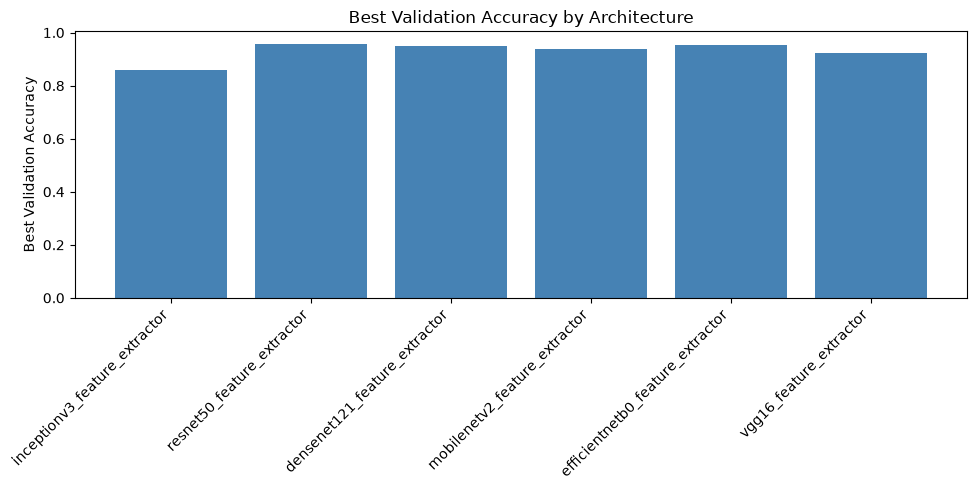

In [18]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Architecture"], results_df["Best Val Accuracy"], color="steelblue")
plt.ylabel("Best Validation Accuracy")
plt.title("Best Validation Accuracy by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

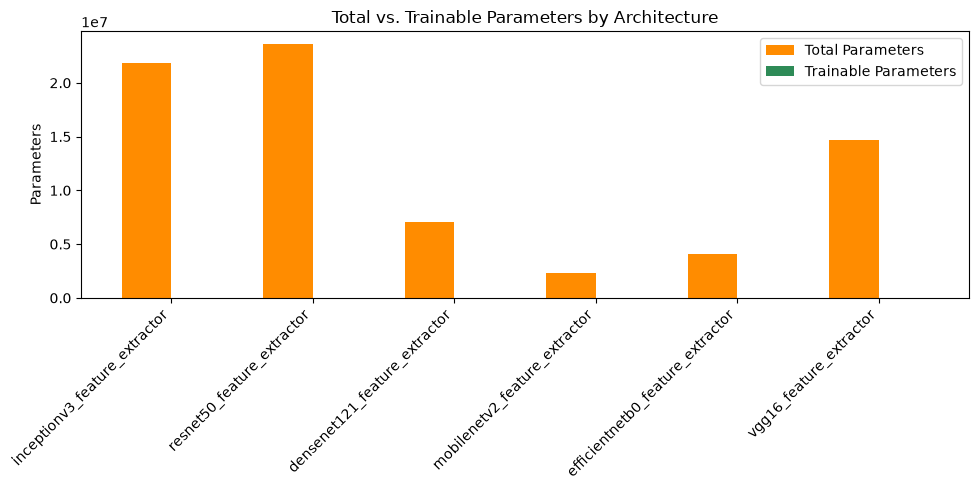

In [19]:
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, results_df["Total Parameters"], width, label="Total Parameters", color="darkorange")
plt.bar(x + width/2, results_df["Trainable Parameters"], width, label="Trainable Parameters", color="seagreen")
plt.xticks(x, results_df["Architecture"], rotation=45, ha="right")
plt.ylabel("Parameters")
plt.title("Total vs. Trainable Parameters by Architecture")
plt.legend()
plt.tight_layout()
plt.show()

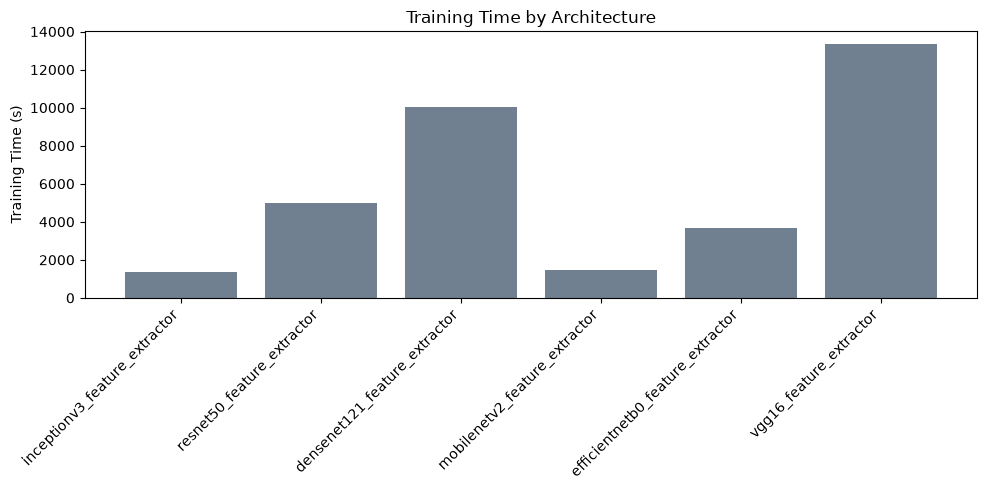

In [20]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Architecture"], results_df["Training Time (s)"], color="slategray")
plt.ylabel("Training Time (s)")
plt.title("Training Time by Architecture")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

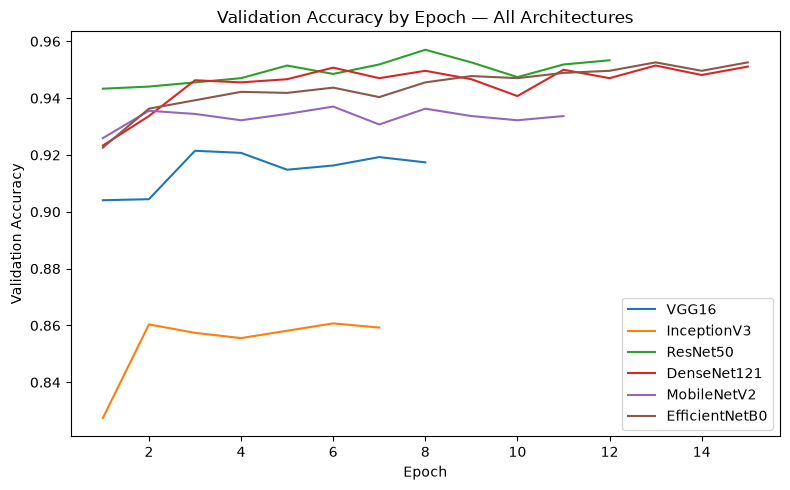

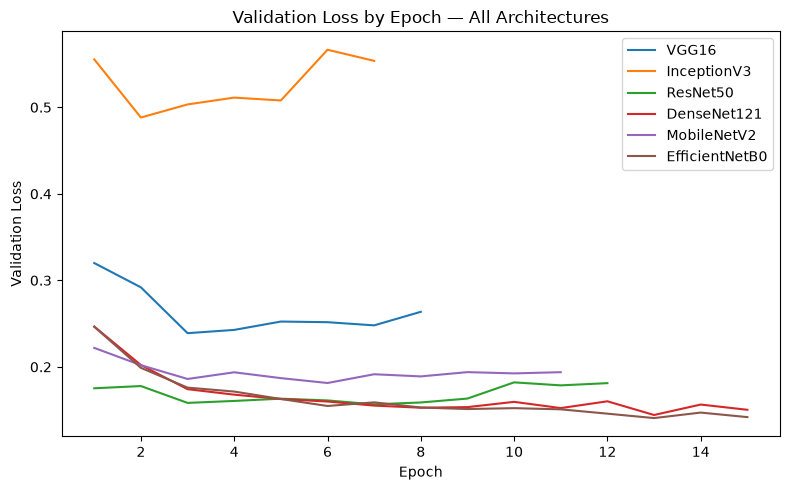

In [21]:
hists = {
    "VGG16": hist_vgg16,
    "InceptionV3": hist_inception,
    "ResNet50": hist_resnet,
    "DenseNet121": hist_densenet,
    "MobileNetV2": hist_mobilenet,
    "EfficientNetB0": hist_efficientnet,
}

plt.figure(figsize=(8, 5))
for label, h in hists.items():
    plt.plot(h.index, h["val_accuracy"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Epoch — All Architectures")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for label, h in hists.items():
    plt.plot(h.index, h["val_loss"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss by Epoch — All Architectures")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Analysis

All numbers below are validation results from single runs under this notebook's setup: every backbone frozen (feature extraction only), 128×128 input, the same classification head and training configuration, and each architecture's own preprocessing. They describe this experiment and are not a general ranking of architectures. The test set was not used.

**Accuracy.** ResNet50 achieved the highest validation accuracy during feature extraction (95.70%), followed by EfficientNetB0 (95.26%), DenseNet121 (95.15%), MobileNetV2 (93.70%), VGG16 (92.15%), and InceptionV3 (86.07%). The top three are within 0.55 percentage points of one another (about 15 of the 2,700 validation images), which is small for single runs, so their order should not be treated as firmly established.

**Loss.** The ordering by validation loss is different. EfficientNetB0 achieved the lowest validation loss (0.1408), followed by DenseNet121 (0.1444), ResNet50 (0.1567), MobileNetV2 (0.1814), VGG16 (0.2390), and InceptionV3 (0.4882). ResNet50 is first on accuracy but third on loss, so the two rankings are reported separately here. The best-accuracy and best-loss epochs also differ for ResNet50 (Epochs 8 and 7) and InceptionV3 (Epochs 6 and 2); `EarlyStopping` restores the best-loss epoch.

**Parameter counts.** Total parameters range from 2,270,794 (MobileNetV2) to 23,608,202 (ResNet50), but accuracy does not follow size: the smallest model (MobileNetV2, 93.70%) beat VGG16 (14.7M parameters, 92.15%) and InceptionV3 (21.8M parameters, 86.07%), while EfficientNetB0 (4.06M) and DenseNet121 (7.05M) came within 0.55 points of ResNet50 (23.6M). Only the classification head was trained, with 5,130 (VGG16) to 20,490 (InceptionV3 and ResNet50) trainable parameters depending on the number of feature channels each backbone outputs, so trainable-parameter counts here do not measure model quality either.

**Training time.** InceptionV3 took 1,374.3 s, MobileNetV2 1,467.6 s, EfficientNetB0 3,671.6 s, ResNet50 5,008.6 s, DenseNet121 10,020.6 s, and VGG16 13,347.0 s. Parameter count alone does not determine training time: DenseNet121, with the third-smallest parameter count (after MobileNetV2 and EfficientNetB0), was the second slowest, and VGG16 was the slowest even though it stopped after only 8 epochs (about 1,668 s per epoch, against about 668 s per epoch for DenseNet121 over 15 epochs). Total time also depends on how many epochs ran before `EarlyStopping` (InceptionV3 7, VGG16 8, MobileNetV2 11, ResNet50 12, DenseNet121 and EfficientNetB0 15) and on the machine: the same frozen ResNet50 run, repeated as Stage A in Notebook 07, took 6,400.3 s instead of 5,008.6 s. The times are therefore indicative, not precise.

**Older and newer designs.** VGG16 (no shortcuts or dense connections) reached 92.15% and was below ResNet50, EfficientNetB0, DenseNet121, and MobileNetV2 in this setup, but above InceptionV3. InceptionV3, a design from the same period as ResNet50, was the weakest at 86.07%. So the age of an architecture did not predict its result here. One possible factor for InceptionV3 is the 128×128 input, which is well below its native 299×299 resolution; this is a possibility, not something this notebook tested.

**Comparison with references.** Five of the six architectures exceeded the Notebook 03 baseline (88.00% / 0.3607) in validation accuracy, and the same five also had lower validation loss. InceptionV3 (86.07% / 0.4882) was below the baseline on both. MobileNetV2 was retrained here, and its result (93.70%, 0.1814, best epoch 6) matched the Notebook 05 run exactly, with identical per-epoch values in both logs. So no run-to-run difference was observed for this architecture in this setup. That is a single repeat of a frozen backbone with a small head and fixed seeds, which leaves little randomness; it does not contradict the larger run-to-run variation seen for from-scratch CNNs in Notebook 04, and it does not show that the other results here would reproduce exactly.


## 17. Key Observations

1. **Accuracy and loss rank the architectures differently.** ResNet50 achieved the highest validation accuracy (95.70%), and EfficientNetB0 achieved the lowest validation loss (0.1408); DenseNet121 was close on both (95.15%, 0.1444). The three are within 0.55 accuracy points of each other, so these single-run differences are small.
2. **Frozen ImageNet features beat the from-scratch baseline for 5 of 6 architectures** in validation accuracy (88.00% baseline), while training only a small classification head (5,130 to 20,490 trainable parameters depending on the backbone).
3. **InceptionV3 was the exception** (86.07%, below the baseline). The 128×128 input is one possible factor, but this notebook did not test it.
4. **Size and speed did not track accuracy.** The smallest model (MobileNetV2) outperformed two much larger ones (VGG16 and InceptionV3), and training time ranged from about 23 minutes (InceptionV3) to about 3 hours 42 minutes (VGG16) without following parameter count. Times depend on the number of epochs run and on the machine.
5. **The MobileNetV2 re-run reproduced Notebook 05 exactly** (93.70% / 0.1814 / Epoch 6), for this frozen setup with fixed seeds.
6. **Candidates for Notebook 07:** ResNet50 (highest validation accuracy) and EfficientNetB0 (lowest validation loss, second-highest accuracy, much shorter run than DenseNet121) are the two architectures carried into fine-tuning, for the reasons given in Notebook 07, Section 6. DenseNet121 was close in accuracy and loss but took 10,020.6 s for feature extraction alone.
7. All comparisons are validation-only, use 128×128 inputs and a single run per architecture, and do not establish a general ranking of these architectures.


## 18. Limitations

- All six architectures were evaluated at 128×128 input resolution rather than their ImageNet-standard input sizes (224×224, or 299×299 for InceptionV3; Section 4) — results might differ, possibly substantially for some architectures, at their native resolution.
- Only frozen-backbone feature extraction was tested; none of these architectures was fine-tuned, so this doesn't measure each architecture's full potential on EuroSAT, only how useful its off-the-shelf ImageNet features are here.
- Every architecture used the identical classification head, learning rate, and training configuration — a per-architecture learning-rate search might change relative rankings, but that would cross into hyperparameter tuning this project intentionally avoids at this stage.
- Results come from single training runs; Notebook 04's combined-regularization experiment showed that CNN training on this dataset can vary noticeably between runs, so any close results between architectures here should be read with that in mind.
- As with every notebook before Notebook 08, all results are validation-only and have not been checked against the held-out test set.

## 19. Conclusion

This notebook compared six ImageNet-pretrained backbones — VGG16, InceptionV3, ResNet50, DenseNet121, MobileNetV2, and EfficientNetB0 — under an identical frozen-feature-extraction setup: same 128×128 input pipeline (with each architecture's own correct preprocessing), same classification head, same training configuration, validation data only. In this comparison, ResNet50 achieved the highest validation accuracy (95.70%) and EfficientNetB0 achieved the lowest validation loss (0.1408), with DenseNet121 close to both (95.15%, 0.1444); MobileNetV2 (93.70%) and VGG16 (92.15%) followed, and InceptionV3 (86.07%) was the only architecture below the 88.00% from-scratch baseline. Accuracy and loss gave different orderings, and neither parameter count nor training time tracked accuracy. These are single-run results for this specific setup (128×128 inputs, frozen backbones), not a general ranking of the architectures, and no final or best model is declared here.

The next step is **Notebook 07 — Fine-Tuning**, where the architecture(s) that performed well here will have some of their upper backbone layers unfrozen and trained with a smaller learning rate, to see whether adapting the pretrained features specifically to EuroSAT improves on today's frozen-feature results. The test set remains untouched until Notebook 08.